# Stagger code ``tabcmp.dat`` EOS consistency check

## Setup

In [7]:
%load_ext autoreload
%autoreload 2

In [8]:
import numpy as np
import matplotlib.pyplot as pl
import scipy
import scipy.io
import scipy.interpolate
import sys
import os

In [9]:
top='c:/cygwin64/home/codes/dispatch2/'
sys.path.insert(0,top+'utilities/python')

In [10]:
import dispatch

## Read EOS data

In [11]:
import dispatch.EOS
eos=dispatch.EOS.open('stagger','tabcmp.dat',top=top,verbose=0)
eos.variables

{0: 'ln(P)', 1: 'rkap', 2: 'E', 3: '', 4: 'S1', 5: 'S2', 6: 'S3', 7: 'S4'}

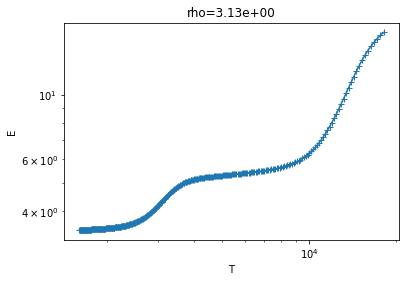

In [13]:
j=300
d=np.exp(eos.scale0.values[j])
theta,lnP=eos.values(j,'ln(P)')
theta,E=eos.values(j,'E')
T=5040/theta
P=np.exp(lnP)
lnT=np.log(T)
lnE=np.log(E)
w=np.where(abs(lnT/np.log(10)-4)<1)[0]
pl.loglog(T[w],E[w],'-+')
pl.title('rho={:.2e}'.format(d))
pl.xlabel('T'); pl.ylabel('E');

## Differences in cross-derivatives

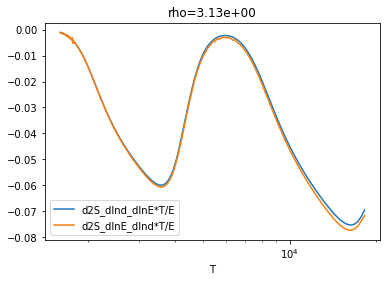

In [14]:
from dispatch.EOS import deriv,interp

def d2S_dlnE_dlnd(j0):
    def dS_dlnE(j):
        theta,E=eos.values(j,'E')
        T=5040/theta
        return E/T,E,T
    j1=j0+1
    dS_dlnE_0,E0,T0=dS_dlnE(j0)        # dS_dlnE on E0 scale
    dS_dlnE_1,E1,T1=dS_dlnE(j1)        # dS_dlnE on E1 scale
    dS_dlnE_1=interp(E1,dS_dlnE_1,E0)  # dS_dlnE on E0 scale
    T1=interp(E1,T1,E0)                # T1 on E0 scale
    lnd_step=eos.scale0.step
    return (dS_dlnE_1-dS_dlnE_0)/lnd_step*(T0+T1)/(E0+E0),T1

def d2S_dlnd_dlnE(j0):
    """ \partial S^2 \over \partial\ln\rho \partial\ln E """
    def d2S(j):
        d=np.exp(eos.scale0.values[j])
        theta,lnP=eos.values(j,'ln(P)')
        theta,E=eos.values(j,'E')
        T=5040/theta
        P=np.exp(lnP)
        lnT=np.log(T)
        lnE=np.log(E)
        dS_dlnd=-P/(d*T)
        return deriv(lnE,dS_dlnd),E,T,lnE
    j1=j0+1
    d2S0,E0,T0,lnE0=d2S(j0)
    d2S1,E1,T1,lnE1=d2S(j1)
    d2S1=interp(E1,d2S1,E0)
    T1=interp(E1,T1,E0)
    return (d2S0+d2S1)/2*(T0+T1)/(E0+E0),T1
i=300
d2S_1,T1=d2S_dlnE_dlnd(i)
d2S_2,T2=d2S_dlnd_dlnE(i)
pl.semilogx(T1,d2S_1,label='d2S_dlnd_dlnE*T/E')
pl.semilogx(T1,d2S_2,label='d2S_dlnE_dlnd*T/E')
d=np.exp(eos.scale0.values[i])
pl.legend(); pl.title('rho={:.2e}'.format(d)); pl.xlabel('T');

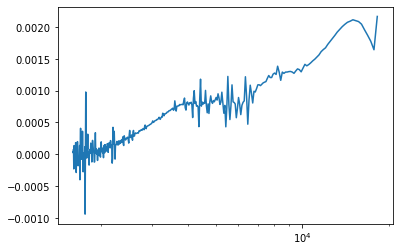

In [15]:
pl.semilogx(T1,d2S_1-d2S_2,label='difference');

Multiple densities:

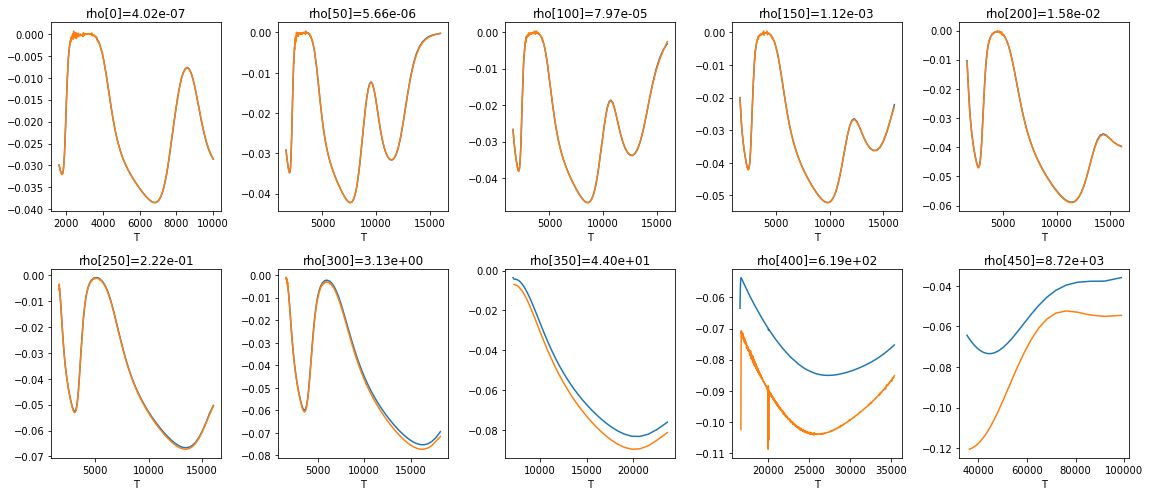

In [24]:
pl.figure(figsize=(16,7))
ip=1
Plot=pl.plot
for i in range(0,eos.scale0.n,50):
    d2S_1,T1=d2S_dlnE_dlnd(i)
    d2S_2,T2=d2S_dlnd_dlnE(i)
    pl.subplot(2,5,ip); ip+=1
    Plot(T1,d2S_1)
    j0=10 if i==400 else 1
    Plot(T1[:-j0],d2S_2[:-j0])
    d=np.exp(eos.scale0.values[i])
    pl.title('rho[{}]={:.2e}'.format(i,d)); pl.xlabel('T');
pl.tight_layout()

These results are similar to the ones for ``48h1/table.dat``, showing that the conversion code in ``tabinv.f90`` works as intended.